# NF-CSE-CIC-IDS2018v2: Dataset Exploration

## Objective
Understand the dataset before preprocessing or modeling.

## Questions
1. What does one row represent?
2. How many observations and features are present?
3. What are the column names and data types?
4. Which column contains the target label?
5. Which attack classes are represented?
6. Is the dataset imbalanced?
7. Are there missing or infinite values?
8. Are duplicate rows present?
9. Is there meaningful temporal information?


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [39]:
df = pd.read_parquet("../data/raw/NF-CSE-CIC-IDS2018-V2.parquet")

In [40]:
df.head()

,L4_SRC_PORT,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,IN_PKTS,OUT_BYTES,OUT_PKTS,TCP_FLAGS,CLIENT_TCP_FLAGS,...,TCP_WIN_MAX_IN,TCP_WIN_MAX_OUT,ICMP_TYPE,ICMP_IPV4_TYPE,DNS_QUERY_ID,DNS_QUERY_TYPE,DNS_TTL_ANSWER,FTP_COMMAND_RET_CODE,Label,Attack
0,40894,22,6,92.0,3164,23,3765,21,27,27,...,26883,26847,0,0,0,0,0,0,1,SSH-Bruteforce
1,29622,3389,6,0.0,1919,14,2031,11,223,219,...,8192,64000,0,0,0,0,0,0,0,Benign
2,65456,53,17,0.0,116,2,148,2,0,0,...,0,0,0,0,2511,1,5,0,0,Benign
3,57918,53,17,0.0,70,1,130,1,0,0,...,0,0,0,0,3371,1,60,0,0,Benign
4,63269,80,6,7.0,232,5,1136,4,223,222,...,8192,26883,0,0,0,0,0,0,1,DDoS attacks-LOIC-HTTP


In [41]:
df.shape

(17129715, 43)

In [42]:
df.columns.tolist()

['L4_SRC_PORT',
 'L4_DST_PORT',
 'PROTOCOL',
 'L7_PROTO',
 'IN_BYTES',
 'IN_PKTS',
 'OUT_BYTES',
 'OUT_PKTS',
 'TCP_FLAGS',
 'CLIENT_TCP_FLAGS',
 'SERVER_TCP_FLAGS',
 'FLOW_DURATION_MILLISECONDS',
 'DURATION_IN',
 'DURATION_OUT',
 'MIN_TTL',
 'MAX_TTL',
 'LONGEST_FLOW_PKT',
 'SHORTEST_FLOW_PKT',
 'MIN_IP_PKT_LEN',
 'MAX_IP_PKT_LEN',
 'SRC_TO_DST_SECOND_BYTES',
 'DST_TO_SRC_SECOND_BYTES',
 'RETRANSMITTED_IN_BYTES',
 'RETRANSMITTED_IN_PKTS',
 'RETRANSMITTED_OUT_BYTES',
 'RETRANSMITTED_OUT_PKTS',
 'SRC_TO_DST_AVG_THROUGHPUT',
 'DST_TO_SRC_AVG_THROUGHPUT',
 'NUM_PKTS_UP_TO_128_BYTES',
 'NUM_PKTS_128_TO_256_BYTES',
 'NUM_PKTS_256_TO_512_BYTES',
 'NUM_PKTS_512_TO_1024_BYTES',
 'NUM_PKTS_1024_TO_1514_BYTES',
 'TCP_WIN_MAX_IN',
 'TCP_WIN_MAX_OUT',
 'ICMP_TYPE',
 'ICMP_IPV4_TYPE',
 'DNS_QUERY_ID',
 'DNS_QUERY_TYPE',
 'DNS_TTL_ANSWER',
 'FTP_COMMAND_RET_CODE',
 'Label',
 'Attack']

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5918803 entries, 0 to 5918802
Data columns (total 12 columns):
 #   Column                      Dtype  
---  ------                      -----  
 0   L4_SRC_PORT                 int32  
 1   L4_DST_PORT                 int32  
 2   PROTOCOL                    int8   
 3   L7_PROTO                    float32
 4   IN_BYTES                    int32  
 5   OUT_BYTES                   int32  
 6   IN_PKTS                     int32  
 7   OUT_PKTS                    int32  
 8   TCP_FLAGS                   int16  
 9   FLOW_DURATION_MILLISECONDS  int32  
 10  Label                       int8   
 11  Attack                      str    
dtypes: float32(1), int16(1), int32(7), int8(2), str(1)
memory usage: 286.0 MB


In [9]:
df["Attack"].value_counts()

Attack
Benign                      5534773
DoS attacks-Hulk             108129
SSH-Bruteforce                71148
Infilteration                 59374
DDoS attacks-LOIC-HTTP        49751
DoS attacks-GoldenEye         32582
DoS attacks-Slowloris         17109
Bot                           15498
DoS attacks-SlowHTTPTest      14116
FTP-BruteForce                14116
DDOS attack-LOIC-UDP           1667
DDOS attack-HOIC                230
Brute Force -Web                173
Brute Force -XSS                101
SQL Injection                    36
Name: count, dtype: int64

In [10]:
df["Label"].value_counts()

Label
0    5534773
1     384030
Name: count, dtype: int64

In [11]:
df[["Label", "Attack"]].value_counts()

Label  Attack                  
0      Benign                      5534773
1      DoS attacks-Hulk             108129
       SSH-Bruteforce                71148
       Infilteration                 59374
       DDoS attacks-LOIC-HTTP        49751
       DoS attacks-GoldenEye         32582
       DoS attacks-Slowloris         17109
       Bot                           15498
       DoS attacks-SlowHTTPTest      14116
       FTP-BruteForce                14116
       DDOS attack-LOIC-UDP           1667
       DDOS attack-HOIC                230
       Brute Force -Web                173
       Brute Force -XSS                101
       SQL Injection                    36
Name: count, dtype: int64

In [12]:
df["Attack"].value_counts(normalize=True) * 100

Attack
Benign                      93.511695
DoS attacks-Hulk             1.826873
SSH-Bruteforce               1.202067
Infilteration                1.003142
DDoS attacks-LOIC-HTTP       0.840558
DoS attacks-GoldenEye        0.550483
DoS attacks-Slowloris        0.289062
Bot                          0.261843
DoS attacks-SlowHTTPTest     0.238494
FTP-BruteForce               0.238494
DDOS attack-LOIC-UDP         0.028164
DDOS attack-HOIC             0.003886
Brute Force -Web             0.002923
Brute Force -XSS             0.001706
SQL Injection                0.000608
Name: proportion, dtype: float64

In [13]:
df["Attack"].nunique()

15

In [14]:
df["Attack"].value_counts().tail(5)

Attack
DDOS attack-LOIC-UDP    1667
DDOS attack-HOIC         230
Brute Force -Web         173
Brute Force -XSS         101
SQL Injection             36
Name: count, dtype: int64

In [15]:
df["Attack"] == "Benign"

0          True
1          True
2          True
3          True
4          True
           ... 
5918798    True
5918799    True
5918800    True
5918801    True
5918802    True
Name: Attack, Length: 5918803, dtype: bool

In [16]:
df.loc[df["Attack"] == "Benign", "Label"]

0          0
1          0
2          0
3          0
4          0
          ..
5918798    0
5918799    0
5918800    0
5918801    0
5918802    0
Name: Label, Length: 5534773, dtype: int8

In [17]:
df.loc[df["Attack"] == "Benign", "Label"].unique()

array([0], dtype=int8)

In [18]:
df.loc[df["Attack"] != "Benign", "Label"].unique()

array([1], dtype=int8)

## Observation
### Label is consistent across attack, it is 0 for benign and 1 for any kind of attack, this makes binary classification possible 

In [20]:
df.isna().sum()

L4_SRC_PORT                   0
L4_DST_PORT                   0
PROTOCOL                      0
L7_PROTO                      0
IN_BYTES                      0
OUT_BYTES                     0
IN_PKTS                       0
OUT_PKTS                      0
TCP_FLAGS                     0
FLOW_DURATION_MILLISECONDS    0
Label                         0
Attack                        0
dtype: int64

### There are no missing values across all 12 columns

In [25]:
df.select_dtypes(include= "number")

,L4_SRC_PORT,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,OUT_BYTES,IN_PKTS,OUT_PKTS,TCP_FLAGS,FLOW_DURATION_MILLISECONDS,Label
0,51128,443,6,91.000000,152,0,3,0,194,4285680,0
1,443,51036,6,91.178001,994,979,7,7,24,4234714,0
2,12262,445,6,0.000000,585,344,5,4,30,4294106,0
3,61023,53,17,0.000000,136,168,2,2,0,4293985,0
4,443,51037,6,91.178001,72,40,1,1,24,4294845,0
...,...,...,...,...,...,...,...,...,...,...,...
5918798,22,40810,6,0.000000,2601,0,12,0,27,0,0
5918799,15476,23,6,0.000000,44,0,1,0,2,0,0
5918800,23,15476,6,0.000000,40,0,1,0,20,0,0
5918801,56407,53,17,0.000000,72,0,1,0,0,0,0


In [26]:
df.select_dtypes(include="number").columns

Index(['L4_SRC_PORT', 'L4_DST_PORT', 'PROTOCOL', 'L7_PROTO', 'IN_BYTES',
       'OUT_BYTES', 'IN_PKTS', 'OUT_PKTS', 'TCP_FLAGS',
       'FLOW_DURATION_MILLISECONDS', 'Label'],
      dtype='str')

In [27]:
df.columns

Index(['L4_SRC_PORT', 'L4_DST_PORT', 'PROTOCOL', 'L7_PROTO', 'IN_BYTES',
       'OUT_BYTES', 'IN_PKTS', 'OUT_PKTS', 'TCP_FLAGS',
       'FLOW_DURATION_MILLISECONDS', 'Label', 'Attack'],
      dtype='str')

In [30]:
np.isinf(df.select_dtypes(include="number")).sum()

L4_SRC_PORT                   0
L4_DST_PORT                   0
PROTOCOL                      0
L7_PROTO                      0
IN_BYTES                      0
OUT_BYTES                     0
IN_PKTS                       0
OUT_PKTS                      0
TCP_FLAGS                     0
FLOW_DURATION_MILLISECONDS    0
Label                         0
dtype: int64

### No column contains infinity values

In [32]:
df.duplicated().sum()

np.int64(0)

### No exact duplicate rows

In [36]:
df.select_dtypes(include = "number").describe()

,L4_SRC_PORT,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,OUT_BYTES,IN_PKTS,OUT_PKTS,TCP_FLAGS,FLOW_DURATION_MILLISECONDS,Label
count,5.918803e+06,5.918803e+06,5.918803e+06,5.918803e+06,5.918803e+06,5.918803e+06,5.918803e+06,5.918803e+06,5.918803e+06,5.918803e+06,5.918803e+06
mean,4.831690e+04,4.085514e+03,9.553450e+00,1.749647e+01,5.151412e+03,6.143053e+03,5.457634e+01,8.183835e+00,7.390662e+01,3.563918e+06,6.488305e-02
std,1.699868e+04,1.178477e+04,5.215247e+00,3.431161e+01,1.555242e+05,3.071493e+05,2.319802e+03,2.110238e+02,9.489872e+01,1.605111e+06,2.463194e-01
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,4.988200e+04,5.300000e+01,6.000000e+00,0.000000e+00,7.400000e+01,8.800000e+01,1.000000e+00,1.000000e+00,0.000000e+00,4.284102e+06,0.000000e+00
50%,5.267000e+04,4.430000e+02,6.000000e+00,0.000000e+00,2.820000e+02,1.980000e+02,4.000000e+00,2.000000e+00,2.600000e+01,4.293672e+06,0.000000e+00
75%,5.796700e+04,3.389000e+03,1.700000e+01,7.000000e+00,1.480000e+03,1.873000e+03,1.000000e+01,7.000000e+00,2.180000e+02,4.294942e+06,0.000000e+00
max,6.553500e+04,6.553500e+04,5.800000e+01,2.480000e+02,2.437127e+07,2.141229e+08,2.799630e+05,1.427980e+05,2.230000e+02,4.294967e+06,1.000000e+00


(array([5.917277e+06, 6.760000e+02, 3.600000e+02, 2.290000e+02,
        2.200000e+01, 1.600000e+01, 1.600000e+01, 8.100000e+01,
        9.900000e+01, 9.000000e+00, 4.000000e+00, 2.000000e+00,
        0.000000e+00, 3.000000e+00, 0.000000e+00, 0.000000e+00,
        1.000000e+00, 0.000000e+00, 0.000000e+00, 0.000000e+00,
        1.000000e+00, 0.000000e+00, 1.000000e+00, 1.000000e+00,
        1.000000e+00, 0.000000e+00, 0.000000e+00, 0.000000e+00,
        0.000000e+00, 0.000000e+00, 0.000000e+00, 0.000000e+00,
        0.000000e+00, 0.000000e+00, 0.000000e+00, 0.000000e+00,
        0.000000e+00, 0.000000e+00, 0.000000e+00, 0.000000e+00,
        0.000000e+00, 0.000000e+00, 3.000000e+00, 0.000000e+00,
        0.000000e+00, 0.000000e+00, 0.000000e+00, 0.000000e+00,
        0.000000e+00, 1.000000e+00]),
 array([     0.  ,   2855.96,   5711.92,   8567.88,  11423.84,  14279.8 ,
         17135.76,  19991.72,  22847.68,  25703.64,  28559.6 ,  31415.56,
         34271.52,  37127.48,  39983.44,  4283

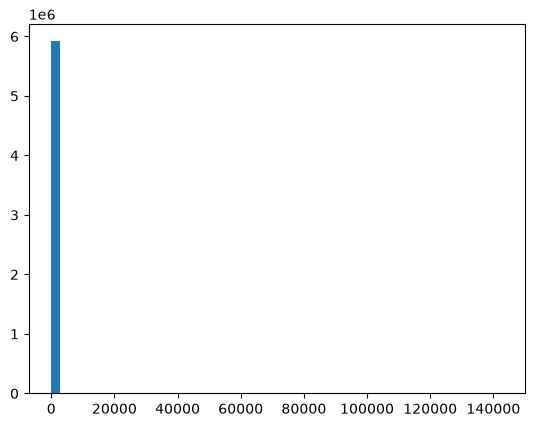

In [37]:
plt.hist(df["OUT_PKTS"], bins=50)


In [38]:
df.columns.tolist()

['L4_SRC_PORT',
 'L4_DST_PORT',
 'PROTOCOL',
 'L7_PROTO',
 'IN_BYTES',
 'OUT_BYTES',
 'IN_PKTS',
 'OUT_PKTS',
 'TCP_FLAGS',
 'FLOW_DURATION_MILLISECONDS',
 'Label',
 'Attack']

In [43]:

# ==========================================
# DATASET INSPECTION: NF-CSE-CIC-IDS2018-V2
# ==========================================

import pandas as pd
import numpy as np

# 1. Dataset size
print("=" * 60)
print("1. DATASET DIMENSIONS")
print("=" * 60)
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

# 2. Column names and data types
print("\n" + "=" * 60)
print("2. SCHEMA AND MEMORY")
print("=" * 60)
df.info()

# 3. Missing values
print("\n" + "=" * 60)
print("3. MISSING VALUES")
print("=" * 60)
missing = df.isna().sum()
print(missing[missing > 0] if missing.any() else "No missing values found.")

# 4. Infinite values in numeric columns
print("\n" + "=" * 60)
print("4. INFINITE VALUES")
print("=" * 60)
numeric_df = df.select_dtypes(include="number")
infinite = pd.Series(
    np.isinf(numeric_df).sum(),
    index=numeric_df.columns
)
print(infinite[infinite > 0] if infinite.any() else "No infinite values found.")

# 5. Exact duplicate rows
print("\n" + "=" * 60)
print("5. DUPLICATE ROWS")
print("=" * 60)
print(f"Exact duplicate rows: {df.duplicated().sum():,}")

# 6. Binary target distribution
print("\n" + "=" * 60)
print("6. BINARY LABEL DISTRIBUTION")
print("=" * 60)
print(df["Label"].value_counts(dropna=False))
print("\nPercentages:")
print((df["Label"].value_counts(normalize=True, dropna=False) * 100).round(3))

# 7. Attack categories
print("\n" + "=" * 60)
print("7. ATTACK CATEGORY DISTRIBUTION")
print("=" * 60)
print(f"Distinct categories: {df['Attack'].nunique(dropna=False)}")
print(df["Attack"].value_counts(dropna=False))
print("\nPercentages:")
print((df["Attack"].value_counts(normalize=True, dropna=False) * 100).round(4))

# 8. Check consistency between Label and Attack
print("\n" + "=" * 60)
print("8. LABEL CONSISTENCY")
print("=" * 60)
print(pd.crosstab(df["Attack"], df["Label"], dropna=False))

# 9. Numeric summary
print("\n" + "=" * 60)
print("9. NUMERIC FEATURE SUMMARY")
print("=" * 60)
print(numeric_df.describe().T.to_string())

# 10. Potentially suspicious values
print("\n" + "=" * 60)
print("10. BASIC RANGE CHECKS")
print("=" * 60)
for col in ["IN_BYTES", "OUT_BYTES", "IN_PKTS", "OUT_PKTS",
            "FLOW_DURATION_MILLISECONDS"]:
    if col in df.columns:
        print(
            f"{col}: min={df[col].min()}, "
            f"max={df[col].max()}, "
            f"zeros={(df[col] == 0).sum():,}, "
            f"negative={(df[col] < 0).sum():,}"
        )

# 11. Save a compact inspection report
print("\n" + "=" * 60)
print("11. INSPECTION COMPLETE")
print("=" * 60)
print("Use the output above to decide preprocessing steps.")


1. DATASET DIMENSIONS
Rows: 17,129,715
Columns: 43

2. SCHEMA AND MEMORY
<class 'pandas.DataFrame'>
RangeIndex: 17129715 entries, 0 to 17129714
Data columns (total 43 columns):
 #   Column                       Dtype  
---  ------                       -----  
 0   L4_SRC_PORT                  int32  
 1   L4_DST_PORT                  int32  
 2   PROTOCOL                     int8   
 3   L7_PROTO                     float32
 4   IN_BYTES                     int32  
 5   IN_PKTS                      int32  
 6   OUT_BYTES                    int32  
 7   OUT_PKTS                     int32  
 8   TCP_FLAGS                    int16  
 9   CLIENT_TCP_FLAGS             int16  
 10  SERVER_TCP_FLAGS             int16  
 11  FLOW_DURATION_MILLISECONDS   int32  
 12  DURATION_IN                  int32  
 13  DURATION_OUT                 int32  
 14  MIN_TTL                      int16  
 15  MAX_TTL                      int16  
 16  LONGEST_FLOW_PKT             int32  
 17  SHORTEST_FLOW_PKT   

/home/krix/Network-Packet-Anomaly-Detector/.venv/lib64/python3.14/site-packages/pandas/core/nanops.py:1028: RuntimeWarning: overflow encountered in square
  sqr = _ensure_numeric((avg - values) ** 2)


                                  count           mean           std   min       25%        50%         75%            max
L4_SRC_PORT                  17129715.0   5.294724e+04  1.152073e+04   0.0   50903.0    54591.0     59793.0   6.553500e+04
L4_DST_PORT                  17129715.0   1.094130e+03  3.297370e+03   0.0      53.0       80.0       445.0   6.553500e+04
PROTOCOL                     17129715.0   1.099481e+01  5.488639e+00   1.0       6.0        6.0        17.0   5.800000e+01
L7_PROTO                     17129715.0   1.124135e+01  2.690619e+01   0.0       0.0        0.0         7.0   2.480000e+02
IN_BYTES                     17129715.0   1.950476e+03  8.362588e+04  28.0      69.0      144.0      1464.0   1.652525e+08
IN_PKTS                      17129715.0   2.516168e+01  1.147684e+03   1.0       1.0        3.0         9.0   2.922690e+05
OUT_BYTES                    17129715.0   7.548850e+03  5.221193e+05   0.0     119.0      294.0      1873.0   2.756398e+08
OUT_PKTS        

In [45]:
# Finish dataset inspection

print("1. EXACT DUPLICATE ROWS")
print(df.duplicated().sum())

print("\n2. BINARY LABEL DISTRIBUTION")
print(df["Label"].value_counts(dropna=False))
print((df["Label"].value_counts(normalize=True) * 100).round(3))

print("\n3. ATTACK CATEGORY DISTRIBUTION")
print(df["Attack"].value_counts(dropna=False))
print("\nPercentages:")
print((df["Attack"].value_counts(normalize=True) * 100).round(4))

print("\n4. LABEL CONSISTENCY")
print(pd.crosstab(df["Attack"], df["Label"], dropna=False))

print("\n5. NUMERIC FEATURE SUMMARY")
print(df.select_dtypes(include="number").describe().T.to_string())

print("\n6. BASIC RANGE CHECKS")
for col in [
    "IN_BYTES", "OUT_BYTES", "IN_PKTS", "OUT_PKTS",
    "FLOW_DURATION_MILLISECONDS"
]:
    print(
        f"{col}: min={df[col].min()}, "
        f"max={df[col].max()}, "
        f"zeros={(df[col] == 0).sum():,}, "
        f"negative={(df[col] < 0).sum():,}"
    )

1. EXACT DUPLICATE ROWS
0

2. BINARY LABEL DISTRIBUTION
Label
0    15101685
1     2028030
Name: count, dtype: int64
Label
0    88.161
1    11.839
Name: proportion, dtype: float64

3. ATTACK CATEGORY DISTRIBUTION
Attack
Benign                      15101685
DDOS attack-HOIC             1066881
DoS attacks-Hulk              432648
DDoS attacks-LOIC-HTTP        207078
Infilteration                 115513
SSH-Bruteforce                 94979
Bot                            28033
DoS attacks-GoldenEye          27723
FTP-BruteForce                 25933
DoS attacks-SlowHTTPTest       14116
DoS attacks-Slowloris           9512
Brute Force -Web                2143
DDOS attack-LOIC-UDP            2112
Brute Force -XSS                 927
SQL Injection                    432
Name: count, dtype: int64

Percentages:
Attack
Benign                      88.1607
DDOS attack-HOIC             6.2282
DoS attacks-Hulk             2.5257
DDoS attacks-LOIC-HTTP       1.2089
Infilteration                0.6743

/home/krix/Network-Packet-Anomaly-Detector/.venv/lib64/python3.14/site-packages/pandas/core/nanops.py:1028: RuntimeWarning: overflow encountered in square
  sqr = _ensure_numeric((avg - values) ** 2)


                                  count           mean           std   min       25%        50%         75%            max
L4_SRC_PORT                  17129715.0   5.294724e+04  1.152073e+04   0.0   50903.0    54591.0     59793.0   6.553500e+04
L4_DST_PORT                  17129715.0   1.094130e+03  3.297370e+03   0.0      53.0       80.0       445.0   6.553500e+04
PROTOCOL                     17129715.0   1.099481e+01  5.488639e+00   1.0       6.0        6.0        17.0   5.800000e+01
L7_PROTO                     17129715.0   1.124135e+01  2.690619e+01   0.0       0.0        0.0         7.0   2.480000e+02
IN_BYTES                     17129715.0   1.950476e+03  8.362588e+04  28.0      69.0      144.0      1464.0   1.652525e+08
IN_PKTS                      17129715.0   2.516168e+01  1.147684e+03   1.0       1.0        3.0         9.0   2.922690e+05
OUT_BYTES                    17129715.0   7.548850e+03  5.221193e+05   0.0     119.0      294.0      1873.0   2.756398e+08
OUT_PKTS        

In [46]:
# Check numeric columns for extreme magnitudes
numeric_df = df.select_dtypes(include="number")

print("Largest absolute value in each numeric column:")
print(numeric_df.abs().max().sort_values(ascending=False).to_string())

Largest absolute value in each numeric column:
SRC_TO_DST_SECOND_BYTES        6.588022e+304
DST_TO_SRC_SECOND_BYTES         3.122086e+73
DST_TO_SRC_AVG_THROUGHPUT       4.294480e+09
SRC_TO_DST_AVG_THROUGHPUT       3.847489e+09
OUT_BYTES                       2.756398e+08
IN_BYTES                        1.652525e+08
FLOW_DURATION_MILLISECONDS      4.294967e+06
RETRANSMITTED_OUT_BYTES         3.656809e+06
IN_PKTS                         2.922690e+05
NUM_PKTS_UP_TO_128_BYTES        2.922690e+05
RETRANSMITTED_IN_BYTES          2.370320e+05
OUT_PKTS                        1.842180e+05
NUM_PKTS_1024_TO_1514_BYTES     1.836310e+05
DNS_TTL_ANSWER                  1.344730e+05
DURATION_IN                     1.067140e+05
L4_DST_PORT                     6.553500e+04
L4_SRC_PORT                     6.553500e+04
TCP_WIN_MAX_IN                  6.553500e+04
DNS_QUERY_ID                    6.553500e+04
TCP_WIN_MAX_OUT                 6.553500e+04
ICMP_TYPE                       6.528000e+04
LONGEST_

In [47]:
print("Attack categories:")
print(df["Attack"].value_counts())

print("\nLabel mapping:")
print(pd.crosstab(df["Attack"], df["Label"]))

print("\nExact duplicate rows:")
print(df.duplicated().sum())

Attack categories:
Attack
Benign                      15101685
DDOS attack-HOIC             1066881
DoS attacks-Hulk              432648
DDoS attacks-LOIC-HTTP        207078
Infilteration                 115513
SSH-Bruteforce                 94979
Bot                            28033
DoS attacks-GoldenEye          27723
FTP-BruteForce                 25933
DoS attacks-SlowHTTPTest       14116
DoS attacks-Slowloris           9512
Brute Force -Web                2143
DDOS attack-LOIC-UDP            2112
Brute Force -XSS                 927
SQL Injection                    432
Name: count, dtype: int64

Label mapping:
Label                            0        1
Attack                                     
Benign                    15101685        0
Bot                              0    28033
Brute Force -Web                 0     2143
Brute Force -XSS                 0      927
DDOS attack-HOIC                 0  1066881
DDOS attack-LOIC-UDP             0     2112
DDoS attacks-LOIC-HTTP   

## Dataset Reconnaissance Summary

### Dataset
- **Name:** NF-CSE-CIC-IDS2018-V2
- **Format:** Parquet
- **Dimensions:** 17,129,715 rows × 43 columns
- **Reported DataFrame memory usage:** Approximately 2.6 GB

### Initial Data Quality
- No missing values were detected.
- No infinite values were detected in numeric columns.
- The exact duplicate-row count remains unconfirmed.
- Numerical summaries triggered an overflow warning due to extreme values in directional bytes-per-second features.

### Target Labels
- `Label = 0`: Benign traffic
- `Label = 1`: Attack traffic
- Cross-tabulation confirmed consistency between `Label` and `Attack`.
- There are 15 categories: benign traffic and 14 attack categories.
- Approximately 88.16% of records are benign and 11.84% are attacks.

### Initial Feature Concerns
- `SRC_TO_DST_SECOND_BYTES` and `DST_TO_SRC_SECOND_BYTES` contain extreme values that require investigation.
- `FTP_COMMAND_RET_CODE` is constant at zero and is not useful as a predictive feature in this dataset.
- `FLOW_DURATION_MILLISECONDS` is zero for a large proportion of records; its interpretation requires further investigation.

### Initial Modeling Plan
- Begin with binary classification using `Label` as the target.
- Preserve `Attack` for later attack-category classification.
- Exclude target columns from model inputs.
- Investigate suspicious features before preprocessing.
- Evaluate using precision, recall, F1-score, and a confusion matrix in addition to accuracy.

### Limitations
These are preliminary findings from dataset inspection. Suspicious values have not yet been fully explained, and no model has been trained.